In [35]:
import pandas as pd

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import plotly.colors as colors
pio.templates.default='plotly_white'

In [36]:
df = pd.read_csv("Sample - Superstore.csv",encoding='latin1')

In [37]:
df.sample(2)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
865,866,CA-2014-149020,1/10/2014,1/15/2014,Standard Class,AJ-10780,Anthony Jacobs,Corporate,United States,Springfield,...,22153,South,OFF-LA-10004272,Office Supplies,Labels,Avery 482,2.890,1,0.0,1.3583
2785,2786,CA-2015-149972,9/21/2015,9/23/2015,First Class,CD-12790,Cynthia Delaney,Home Office,United States,Los Angeles,...,90036,West,FUR-CH-10004997,Furniture,Chairs,Hon Every-Day Series Multi-Task Chairs,601.536,4,0.2,0.0000


In [38]:
df.shape

(9994, 21)

In [39]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [41]:
df['Order Date']= pd.to_datetime(df['Order Date'])

In [42]:
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

In [43]:
df['Order Month'] =df['Order Date'].dt.month

In [44]:
df['Order Year']= df['Order Date'].dt.year

In [45]:
df['order of Week']= df['Order Date'].dt.dayofweek

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

## 1. you need to calculate the monthly sales of the store and identify which month had the highest sales and which month had lowest sales 

In [47]:
sales_by_month = df.groupby('Order Month')['Sales'].sum().reset_index()

In [48]:
sales_by_month

,Order Month,Sales
0,1,94924.8356
1,2,59751.2514
2,3,205005.4888
3,4,137762.1286
4,5,155028.8117
5,6,152718.6793
6,7,147238.0970
7,8,159044.0630
8,9,307649.9457
9,10,200322.9847


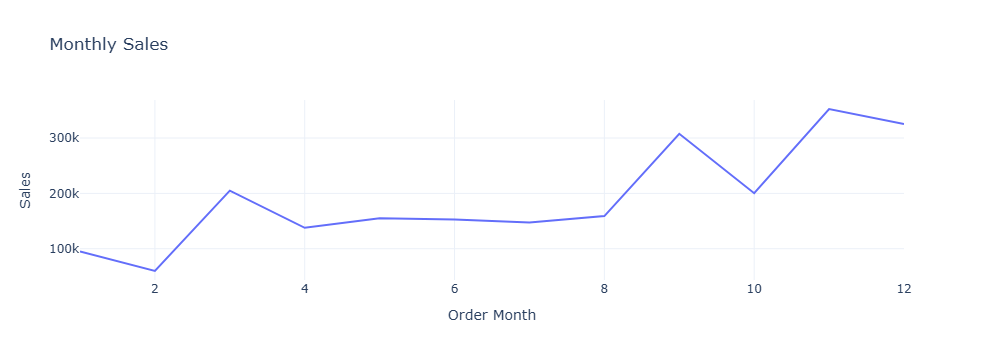

In [49]:
fig = px.line(sales_by_month,
             x='Order Month',
             y='Sales',
             title='Monthly Sales')
fig.show()

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

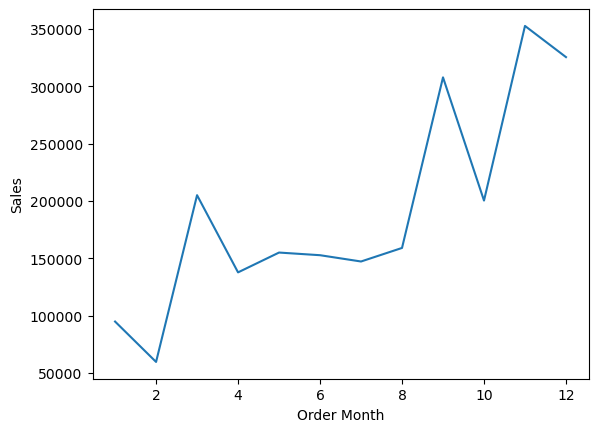

In [53]:
sns.lineplot(data=sales_by_month,x='Order Month',y='Sales')
plt.show()

## you need to analyze sales based on product categories and determine which categories has the highest sales and which categories has lowest sales 

In [55]:
df.sample(2)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Month,Order Year,order of Week
3684,3685,CA-2015-132626,2015-07-09,2015-07-14,Standard Class,BT-11680,Brian Thompson,Consumer,United States,Clinton,...,Office Supplies,Binders,Wilson Jones Active Use Binders,43.680,6,0.0,21.4032,7,2015,3
6596,6597,CA-2017-157112,2017-04-23,2017-04-26,First Class,GG-14650,Greg Guthrie,Corporate,United States,Columbus,...,Office Supplies,Paper,Xerox 195,5.344,1,0.2,1.8704,4,2017,6


In [60]:
sales_by_category = df.groupby('Category')['Sales'].sum().reset_index()

In [61]:
sales_by_category

,Category,Sales
0,Furniture,741999.7953
1,Office Supplies,719047.0320
2,Technology,836154.0330


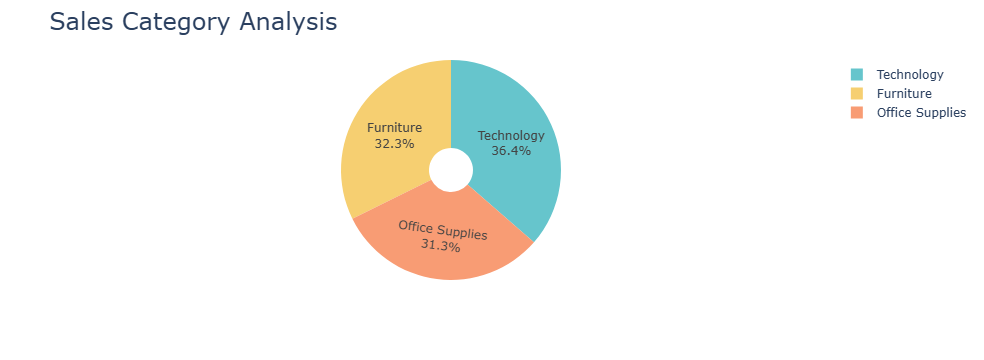

In [67]:

fig = px.pie(sales_by_category,
            values='Sales',
            names='Category',
            #title='Sales by category',
            hole=0.2,
            color_discrete_sequence=px.colors.qualitative.Pastel)
fig.update_traces(textposition='inside',textinfo='percent+label')
fig.update_layout(title_text ='Sales Category Analysis',title_font=dict(size=24))


## the sales analysis need to be done based on sub categories 

In [70]:
sales_by_subcategory = df.groupby('Sub-Category')['Sales'].sum().reset_index()

In [72]:
sales_by_subcategory

,Sub-Category,Sales
0,Accessories,167380.3180
1,Appliances,107532.1610
2,Art,27118.7920
3,Binders,203412.7330
4,Bookcases,114879.9963
5,Chairs,328449.1030
6,Copiers,149528.0300
7,Envelopes,16476.4020
8,Fasteners,3024.2800
9,Furnishings,91705.1640


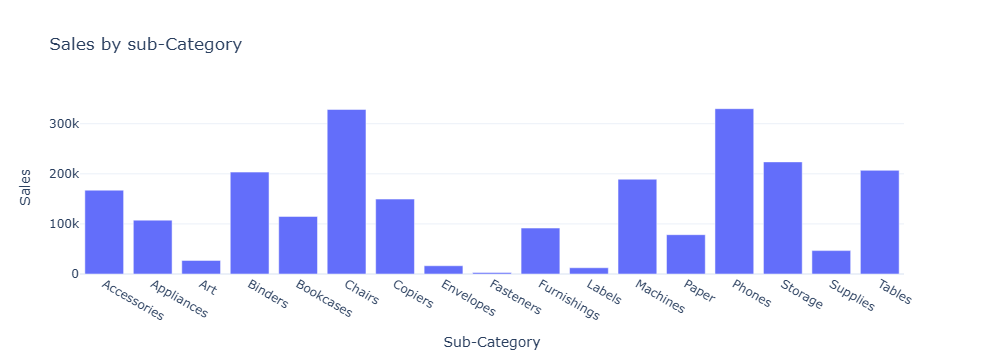

In [73]:
fig = px.bar(sales_by_subcategory,
             x='Sub-Category',
             y='Sales',
             title= 'Sales by sub-Category')
fig.show()

## you need to analyze the monthly profit from sales and determine which month had the highest profit

In [74]:
sales_month_profit = df.groupby('Order Month')['Profit'].sum().reset_index()

In [75]:
sales_month_profit

,Order Month,Profit
0,1,9134.4461
1,2,10294.6107
2,3,28594.6872
3,4,11587.4363
4,5,22411.3078
5,6,21285.7954
6,7,13832.6648
7,8,21776.9384
8,9,36857.4753
9,10,31784.0413


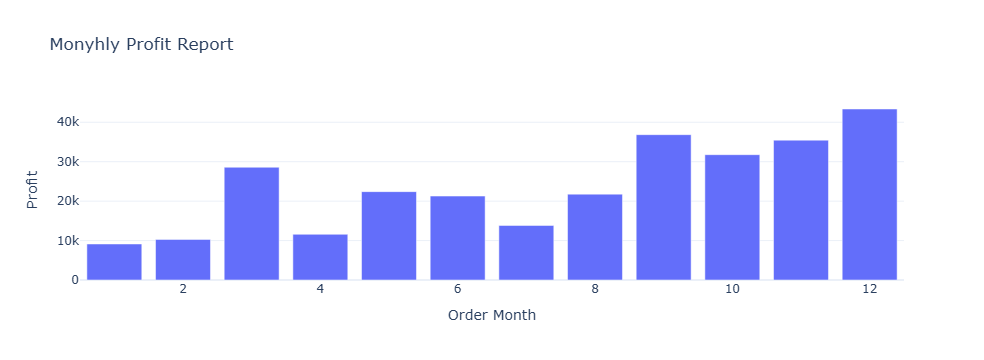

In [77]:
fig=px.bar(sales_month_profit,
      x='Order Month',
      y='Profit',
      title='Monyhly Profit Report')
fig.show()

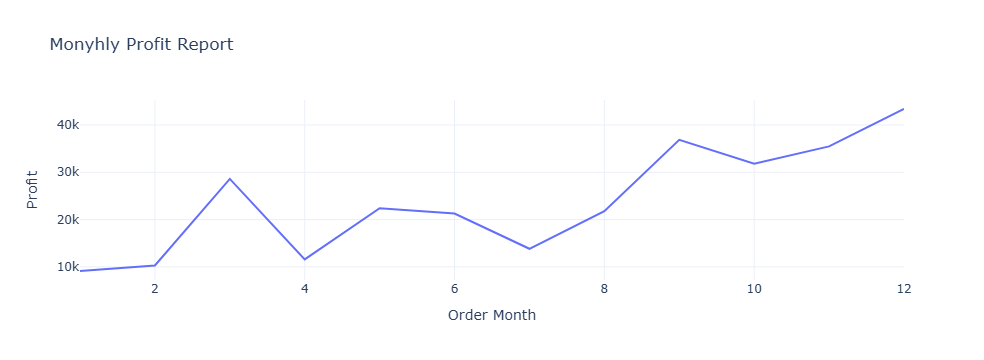

In [78]:
fig=px.line(sales_month_profit,
      x='Order Month',
      y='Profit',
      title='Monyhly Profit Report')
fig.show()

## anlayze the profit too sub-category

In [81]:
profit_by_subcategory = df.groupby('Sub-Category')['Profit'].sum().reset_index()

In [82]:
profit_by_subcategory

,Sub-Category,Profit
0,Accessories,41936.6357
1,Appliances,18138.0054
2,Art,6527.7870
3,Binders,30221.7633
4,Bookcases,-3472.5560
5,Chairs,26590.1663
6,Copiers,55617.8249
7,Envelopes,6964.1767
8,Fasteners,949.5182
9,Furnishings,13059.1436


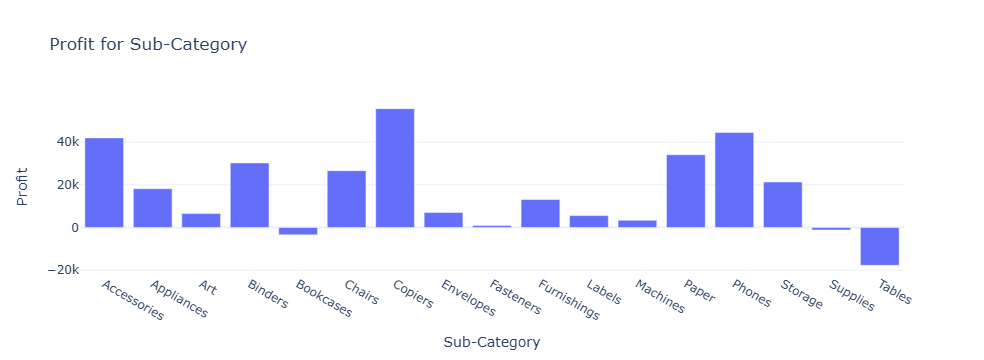

In [84]:
fig = px.bar(profit_by_subcategory,
              x='Sub-Category',
              y='Profit',
              title='Profit for Sub-Category')
fig.show()

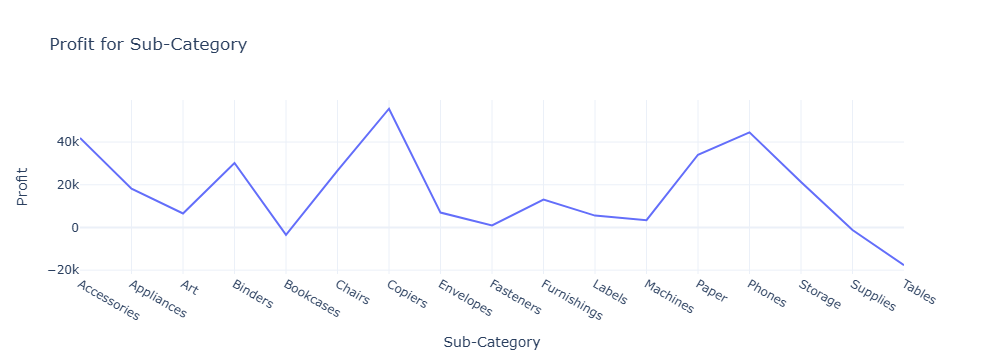

In [83]:
fig = px.line(profit_by_subcategory,
              x='Sub-Category',
              y='Profit',
              title='Profit for Sub-Category')
fig.show()

## analyze the sales and profit by customer segment

In [88]:
sales_by_profit_segment = df.groupby('Segment').agg({'Profit':'sum','Sales':'sum'}).reset_index()

In [89]:
sales_by_profit_segment

,Segment,Profit,Sales
0,Consumer,134119.2092,1.161401e+06
1,Corporate,91979.1340,7.061464e+05
2,Home Office,60298.6785,4.296531e+05


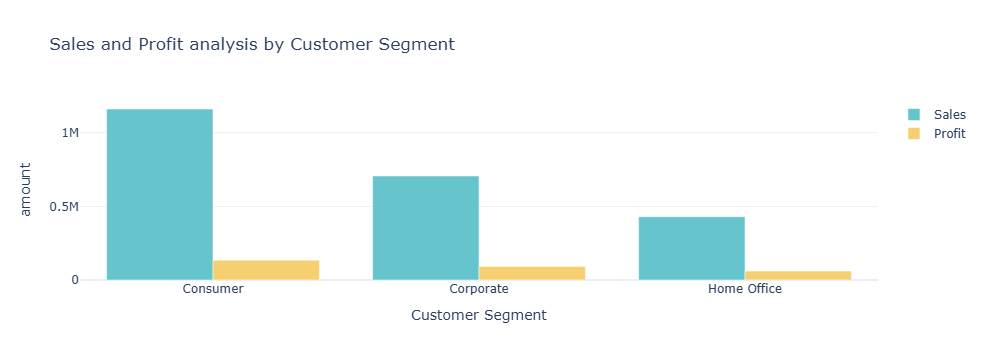

In [91]:
color_pallate = colors.qualitative.Pastel

fig = go.Figure()
fig.add_trace(go.Bar(x=sales_by_profit_segment['Segment'],
                    y=sales_by_profit_segment['Sales'],
                    name='Sales',
                    marker_color=color_pallate[0]))
              
fig.add_trace(go.Bar(x=sales_by_profit_segment['Segment'],
                     y=sales_by_profit_segment['Profit'],
                     name='Profit',
                     marker_color=color_pallate[1]))
fig.update_layout(title='Sales and Profit analysis by Customer Segment',
                 xaxis_title='Customer Segment',yaxis_title='amount')
fig.show()

##  Analysis the Sales to Profit Ratio

In [95]:
sales_profit_by_segment = df.groupby('Segment').agg({'Profit':'sum','Sales':'sum'}).reset_index()
sales_profit_by_segment['Sales_profit_Ratio'] = (sales_profit_by_segment['Sales'] / sales_profit_by_segment['Profit'])
print(sales_profit_by_segment[['Segment','Sales_profit_Ratio']])

       Segment  Sales_profit_Ratio
0     Consumer            8.659471
1    Corporate            7.677245
2  Home Office            7.125416
